# Extract Spiking Traces

This notebook loads a trained SNN checkpoint, runs a single validation inference pass, captures time-by-neuron spike activity from spiking layers, and saves those traces for later heatmaps and animations.

It uses checkpoint weights only during evaluation, so it does not depend on the saved optimizer state matching the current notebook session.


In [1]:
from contextlib import nullcontext
from pathlib import Path
import sys
import json
import math

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
from omegaconf import OmegaConf

ROOT = Path('..').resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from trainer import BrainToTextDecoder_Trainer
from models.neurons import LTLIFNode

plt.style.use('seaborn-v0_8-whitegrid')
torch.set_grad_enabled(False)


In [2]:
# Configure the run and extraction behavior.
RUN_DIR = Path('../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592')
CHECKPOINT_NAME = 'best_checkpoint'
BATCH_INDEX = 0
SAMPLE_INDEX = 0
MAX_NEURONS_TO_SAVE = 256
SAVE_SUBDIR = 'analysis_exports/spiking_traces'

CHECKPOINT_PATH = RUN_DIR / 'checkpoints' / CHECKPOINT_NAME
ARGS_PATH = RUN_DIR / 'checkpoints' / 'args.yaml'
OUTPUT_DIR = RUN_DIR / SAVE_SUBDIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Run dir:', RUN_DIR.resolve())
print('Checkpoint:', CHECKPOINT_PATH.resolve())
print('Args:', ARGS_PATH.resolve())
print('Output dir:', OUTPUT_DIR.resolve())
assert CHECKPOINT_PATH.exists(), f'Checkpoint not found: {CHECKPOINT_PATH}'
assert ARGS_PATH.exists(), f'Args file not found: {ARGS_PATH}'


Run dir: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592
Checkpoint: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/checkpoints/best_checkpoint
Args: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/checkpoints/args.yaml
Output dir: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/analysis_exports/spiking_traces


In [3]:
args = OmegaConf.load(ARGS_PATH)
args.mode = 'eval'
args.init_from_checkpoint = False
args.save_val_logits = False
args.save_val_data = False
args.num_training_batches = 0
args.dataset.num_dataloader_workers = 0
args.dataset.loader_shuffle = False
args.dataset.dataset_dir = str((ROOT / args.dataset.dataset_dir).resolve())
print('Resolved dataset_dir:', args.dataset.dataset_dir)

trainer = BrainToTextDecoder_Trainer(args)
checkpoint = torch.load(str(CHECKPOINT_PATH), map_location=trainer.device, weights_only=False)
load_result = trainer.model.load_state_dict(checkpoint['model_state_dict'])
trainer.model.to(trainer.device)
trainer.model.eval()

print('Device:', trainer.device)
print('Model type:', args.model_type)
print('Loaded model weights from checkpoint only.')
print('Missing keys:', list(load_result.missing_keys))
print('Unexpected keys:', list(load_result.unexpected_keys))
if 'val_PER' in checkpoint:
    print('Checkpoint val_PER:', checkpoint['val_PER'])
if 'val_loss' in checkpoint:
    print('Checkpoint val_loss:', checkpoint['val_loss'])


Resolved dataset_dir: /home/alex/snn_for_bts/brain_to_text/data/hdf5_data_final
2026-04-09 09:24:16,837: EXPERIMENT_TAG: best arch 60k 0-7 data structure test
2026-04-09 09:24:17,088: Using device: cuda:0
(0, 1, 2, 3, 4, 5, 6, 7)
(0, 1, 2, 3, 4, 5, 6, 7)
(0, 1, 2, 3, 4, 5, 6, 7)
(0, 1, 2, 3, 4, 5, 6, 7)
[SNN] enabled blocks: ['input_proj', 'snn_core_x4', 'classifier']
2026-04-09 09:24:20,148: Initialized SNN decoding model
2026-04-09 09:24:20,149: Initialized decoding model
2026-04-09 09:24:20,150: SpikingModel(
  (day_layer_activation): Softsign()
  (day_weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 512x512]
      (1): Parameter containing: [torch.float32 of size 512x512]
      (2): Parameter containing: [torch.float32 of size 512x512]
      (3): Parameter containing: [torch.float32 of size 512x512]
      (4): Parameter containing: [torch.float32 of size 512x512]
      (5): Parameter containing: [torch.float32 of size 512x512]
      (6): Parameter co

In [4]:
trace_store = {}
hook_handles = []

def _extract_sample_trace(spikes, sample_index):
    spikes = spikes.detach().float()

    # Expected SNN layout is [T, B, ...]. This also handles already-single-sample [T, ...].
    if spikes.dim() == 0:
        return None
    if spikes.dim() == 1:
        return spikes.reshape(-1, 1)
    if spikes.dim() == 2:
        return spikes.reshape(spikes.shape[0], -1)

    sample_index = min(sample_index, max(0, spikes.shape[1] - 1))
    return spikes[:, sample_index].reshape(spikes.shape[0], -1)

def register_spike_hooks(model):
    for name, module in model.named_modules():
        if not isinstance(module, LTLIFNode):
            continue

        def hook(mod, inputs, output, layer_name=name):
            if not isinstance(output, torch.Tensor):
                return

            trace = _extract_sample_trace(output, SAMPLE_INDEX)
            if trace is None:
                return

            if MAX_NEURONS_TO_SAVE is not None:
                trace = trace[:, :MAX_NEURONS_TO_SAVE]

            trace_store[layer_name] = {
                'trace': trace.cpu().numpy(),
                'num_neurons': int(trace.shape[1]),
                'time_steps': int(trace.shape[0]),
                'mean_activity': float(trace.mean().item()),
            }

        hook_handles.append(module.register_forward_hook(hook))

register_spike_hooks(trainer.model)
print('Registered hooks for', len(hook_handles), 'spiking layers')


Registered hooks for 4 spiking layers


In [5]:
val_iter = iter(trainer.val_loader)
for _ in range(BATCH_INDEX):
    next(val_iter)
batch = next(val_iter)

features = batch['input_features'].to(trainer.device)
labels = batch['seq_class_ids'].to(trainer.device)
n_time_steps = batch['n_time_steps'].to(trainer.device)
phone_seq_lens = batch['phone_seq_lens'].to(trainer.device)
day_indicies = batch['day_indicies'].to(trainer.device)
session_ids = batch.get('session_ids', batch['day_indicies']).to(trainer.device)

features, n_time_steps = trainer.transform_data(features, n_time_steps, 'val')
adjusted_lens = trainer.compute_output_lengths(n_time_steps)
session_summaries = trainer._lookup_session_summaries(session_ids)

use_cuda_amp = bool(getattr(args, 'use_amp', False)) and str(trainer.device).startswith('cuda')
autocast_context = torch.autocast(device_type='cuda', dtype=torch.float16) if use_cuda_amp else nullcontext()

with torch.no_grad():
    with autocast_context:
        logits = trainer.model(features, day_indicies, session_summary=session_summaries)

adjusted_lens = torch.clamp(adjusted_lens, max=logits.shape[1])
sample_idx = min(SAMPLE_INDEX, max(0, logits.shape[0] - 1))
sample_valid_steps = int(adjusted_lens[sample_idx].item())

decoded_seq = torch.argmax(logits[sample_idx, :sample_valid_steps], dim=-1)
decoded_seq = torch.unique_consecutive(decoded_seq, dim=-1)
decoded_seq = decoded_seq[decoded_seq != 0].detach().cpu().numpy()
true_seq = labels[sample_idx, : phone_seq_lens[sample_idx]].detach().cpu().numpy()

print('Captured layers:', len(trace_store))
print('Batch index:', BATCH_INDEX)
print('Batch size:', int(logits.shape[0]))
print('Sample index:', sample_idx)
print('Valid time steps for sample:', sample_valid_steps)
print('Decoded sequence length:', int(decoded_seq.shape[0]))
print('True sequence length:', int(true_seq.shape[0]))


Captured layers: 4
Batch index: 0
Batch size: 16
Sample index: 0
Valid time steps for sample: 227
Decoded sequence length: 38
True sequence length: 36


In [6]:
manifest = {
    'run_dir': str(RUN_DIR.resolve()),
    'checkpoint_path': str(CHECKPOINT_PATH.resolve()),
    'batch_index': int(BATCH_INDEX),
    'sample_index': int(sample_idx),
    'sample_valid_steps': int(sample_valid_steps),
    'trial_metadata': {
        'day_index': int(batch['day_indicies'][sample_idx].item()),
        'block_num': int(batch['block_nums'][sample_idx].item()),
        'trial_num': int(batch['trial_nums'][sample_idx].item()),
        'session_id': int(session_ids[sample_idx].item()),
        'transcription': str(batch['transcriptions'][sample_idx]),
    },
    'layers': {},
}

for layer_name, info in trace_store.items():
    trimmed_trace = info['trace'][:sample_valid_steps]
    safe_name = layer_name.replace('.', '_')
    out_path = OUTPUT_DIR / f'{safe_name}_spike_trace.npz'
    np.savez_compressed(out_path, trace=trimmed_trace)
    manifest['layers'][layer_name] = {
        'trace_path': str(out_path.resolve()),
        'time_steps': int(trimmed_trace.shape[0]),
        'num_neurons': int(trimmed_trace.shape[1]),
        'mean_activity': float(trimmed_trace.mean()) if trimmed_trace.size else 0.0,
    }

manifest_path = OUTPUT_DIR / 'manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved manifest to', manifest_path)
print('Saved trace files:', len(manifest['layers']))


Saved manifest to ../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/analysis_exports/spiking_traces/manifest.json
Saved trace files: 4


In [26]:
for layer_name, info in list(trace_store.items())[:4]:
    trace = info['trace'][:sample_valid_steps]
    print(layer_name, np.unique(trace), trace.min(), trace.max())


backbone.snn_core.0.neuron [0. 1.] 0.0 1.0
backbone.snn_core.1.neuron [0. 1.] 0.0 1.0
backbone.snn_core.2.neuron [0. 1.] 0.0 1.0
backbone.snn_core.3.neuron [0. 1.] 0.0 1.0


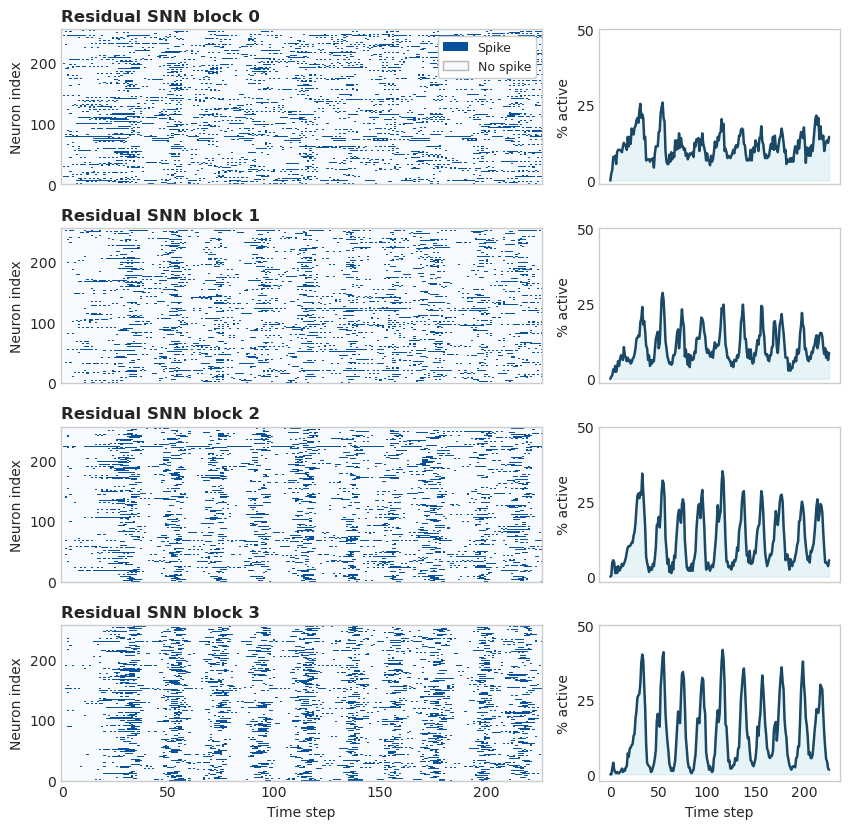

In [36]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

SPIKE_CMAP = ListedColormap(['#f7fbff', '#08519c'])
selected_layers = list(trace_store.items())[:4]

fig, axes = plt.subplots(
    len(selected_layers),
    2,
    figsize=(8.6, 8.4),
    sharex='col',
    gridspec_kw={'width_ratios': [4.0, 2.0]}
)

if len(selected_layers) == 1:
    axes = np.array([axes])

legend_handles = [
    Patch(facecolor='#08519c', edgecolor='none', label='Spike'),
    Patch(facecolor='#f7fbff', edgecolor='0.7', label='No spike'),
]

for row, (layer_name, info) in enumerate(selected_layers):
    trace = info['trace'][:sample_valid_steps]
    spike_fraction = 100.0 * trace.mean(axis=1)
    layer_idx = layer_name.split('.')[-2]

    ax = axes[row, 0]
    ax_rate = axes[row, 1]

    ax.imshow(
        trace.T,
        aspect='auto',
        origin='lower',
        interpolation='nearest',
        cmap=SPIKE_CMAP,
        vmin=0,
        vmax=1,
    )
    ax.set_title(
        f'Residual SNN block {layer_idx}',
        loc='left',
        fontsize=12,
        fontweight='bold',
    )
    ax.set_ylabel('Neuron index')
    ax.grid(False)

    ax_rate.plot(
        np.arange(trace.shape[0]),
        spike_fraction,
        color='#1b4965',
        linewidth=1.8,
    )
    ax_rate.fill_between(
        np.arange(trace.shape[0]),
        spike_fraction,
        color='#62b6cb',
        alpha=0.15,
    )
    ax_rate.set_ylabel('% active')
    ax_rate.set_yticks([0, 25, 50])

    ax_rate.grid(False)

axes[0, 0].legend(
    handles=legend_handles,
    loc='upper right',
    frameon=True,
    facecolor='white',
    edgecolor='0.8',
    framealpha=1.0,
    fontsize=9,
)

axes[-1, 0].set_xlabel('Time step')
axes[-1, 1].set_xlabel('Time step')

plt.tight_layout()
plt.show()


## Optional Animation Preview

This previews a single saved trace as an inline animation by reshaping the neuron axis into an approximate square image.


In [8]:
def reshape_to_square(frame):
    side = int(math.ceil(math.sqrt(frame.shape[0])))
    padded = np.full(side * side, np.nan, dtype=np.float32)
    padded[: frame.shape[0]] = frame.astype(np.float32)
    return padded.reshape(side, side)

EXPORT_GIF = True
GIF_FPS = 8

layer_names = list(trace_store.keys())
if layer_names:
    layer_name = layer_names[0]
    trace = trace_store[layer_name]['trace'][:sample_valid_steps]
    vmax = max(1.0, float(np.nanmax(trace)))
    fig, ax = plt.subplots(figsize=(6.2, 6.2))
    image = ax.imshow(reshape_to_square(trace[0]), interpolation='nearest', cmap=SPIKE_CMAP, vmin=0.0, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{layer_name} | t=0', fontsize=13)
    corner_text = ax.text(
        0.02,
        0.98,
        f'% active: {100.0 * trace[0].mean():.1f}%',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        color='white',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='black', alpha=0.35, edgecolor='none')
    )
    cbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Spike value')

    def update(frame_idx):
        image.set_data(reshape_to_square(trace[frame_idx]))
        ax.set_title(f'{layer_name} | t={frame_idx}')
        corner_text.set_text(f'% active: {100.0 * trace[frame_idx].mean():.1f}%')
        return (image, corner_text)

    anim = animation.FuncAnimation(fig, update, frames=trace.shape[0], interval=120, blit=False)
    plt.close(fig)
    html = anim.to_jshtml(default_mode='loop')
    html = html.replace('.pause()', '.play()')
    display(HTML(html))

    if EXPORT_GIF:
        gif_path = OUTPUT_DIR / f"{layer_name.replace('.', '_')}_preview.gif"
        try:
            writer = animation.PillowWriter(fps=GIF_FPS)
            anim.save(gif_path, writer=writer)
            print('Saved GIF to', gif_path)
            print('You can usually upload that GIF to Notion directly.')
        except Exception as exc:
            print('Could not save GIF:', exc)
else:
    print('No traces captured.')


Saved GIF to ../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/analysis_exports/spiking_traces/backbone_snn_core_0_neuron_preview.gif
You can usually upload that GIF to Notion directly.


In [9]:
for handle in hook_handles:
    handle.remove()
trainer.close()
print('Cleaned up hooks and trainer.')


Cleaned up hooks and trainer.
